In [20]:
import os
os.environ["OMP_NUM_THREADS"] = "4"

In [21]:
from pennylane import numpy as np
import pennylane as qml
import itertools
from itertools import combinations
from scipy.optimize import minimize
from math import comb
import qaoa_aux 

In [22]:
def U_B(beta,edge_list):
    for edge_idx, (u, v) in enumerate(edge_list):
        theta = beta[edge_idx]
        qml.S(wires=u)
        qml.SingleExcitationMinus(-2 * theta,wires=[u, v])
        qml.adjoint(qml.S)(wires=u)

In [23]:
def U_C(gamma,cost_terms):
    # we have term index + cost terms so all the even numbered ZZ's
    for term_idx, (_, wires, coeff) in enumerate(cost_terms):
        theta = 2 * gamma[term_idx] * coeff
        # example for 4 consectuve z's
        #qml.PauliRot(theta, "ZZZZ", wires=[0,1,2,3])
        qml.PauliRot(theta,"Z" * len(wires),wires=list(wires))

In [24]:
def objective(gammas, betas, circuit,hyperedge_list, cost_terms, weights):
    expectation_values = circuit(gammas, betas)

    # Store weighted expected cut value for each hyperedge
    edge_values = []
    for edge_idx, edge in enumerate(hyperedge_list):
        k = len(edge)
        # Weighted constant term for this hyperedge
        edge_value = weights[edge_idx] * (1 - 1 / (2 ** (k - 1)))

        # Add the Pauli-Z terms belonging to this hyperedge
        for term_idx, (source_edge_idx, wires, coeff) in enumerate(cost_terms):

            if source_edge_idx == edge_idx:
                edge_value += coeff * expectation_values[term_idx]

        edge_values.append(edge_value)

    # Negative because Adam minimizes
    return -qml.math.min(qml.math.stack(edge_values))

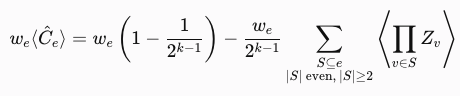

In [25]:

def run_qaoa(
    hyperedge_list,
    n,
    weights,
    num_layers=1,
    seed=42,
    scaling_constant=0.1,
    step_size=0.01,
    max_trials=100
):
    n_wires = n
    assert len(weights) == len(hyperedge_list)

    # Build mixer edges and cost terms
    edge_list = qaoa_aux.clique_expansion(hyperedge_list)
    cost_terms = qaoa_aux.build_cost_terms(hyperedge_list, weights)

    # Balanced initial state
    target_weight = (n_wires + 1) // 2
    initial_state = qaoa_aux.make_dicke_state(n_wires, target_weight)

    dev = qml.device("lightning.qubit", wires=n_wires,batch_obs=True)

    @qml.qnode(dev)
    def circuit(gammas, betas):
        qml.StatePrep(initial_state, wires=range(n_wires))

        for layer in range(num_layers):
            U_C(gammas[:, layer], cost_terms)
            U_B(betas[:, layer], edge_list)

        observables = []

        for _, wires, _ in cost_terms:
            z_term = qml.prod(*[qml.PauliZ(wire) for wire in wires])
            observables.append(qml.expval(z_term))

        return observables

    # Random parameter initialization
    rng = np.random.default_rng(seed)

    beta_params = np.array(
        scaling_constant * rng.random((len(edge_list), num_layers)),
        requires_grad=True
    )

    gamma_params = np.array(
        scaling_constant * rng.random((len(cost_terms), num_layers)),
        requires_grad=True
    )

    opt = qml.AdamOptimizer(stepsize=step_size)
    objective_values = []

    # Fair-cut objective returns NEGATIVE minimum coverage bc maximization problem but adam needs to minimize
    initial_loss = objective(gamma_params, beta_params, circuit,hyperedge_list, cost_terms, weights)

    objective_values.append(-float(initial_loss))

    print(f"Initial fair cut = {-float(initial_loss):.6f}")

    # Optimization
    for trial in range(max_trials):

        gamma_params, beta_params = opt.step(
            lambda g, b: objective(
                g,
                b,
                circuit,
                hyperedge_list,
                cost_terms,
                weights
            ),
            gamma_params,
            beta_params
        )

        current_loss = objective(gamma_params, beta_params, circuit,hyperedge_list, cost_terms, weights)

        fair_cut_value = -float(current_loss)
        objective_values.append(fair_cut_value)

        # if trial % 10 == 0:
        #     print(
        #         f"Iteration {trial:3d} | "
        #         f"fair cut = {fair_cut_value:.6f}"
        #     )
    print(f"Final fair cut = {fair_cut_value:.6f}")
    return {
        "gammas": gamma_params,
        "betas": beta_params,
        "objective_values": objective_values,
        "circuit": circuit,
        "edge_list": edge_list,
        "cost_terms": cost_terms,
        "n_wires": n_wires
    }


In [26]:
P = np.load("../data/poisson_16_12_3/P/03.npy")
w= np.load("../data/poisson_16_12_3/w/03.npy")

hyperedge_list = qaoa_aux.matrix_to_hyperedges(P)

In [27]:

# result = run_qaoa(
#     hyperedge_list,
#     weights=w,
#     n=12,
#     num_layers=3,
#     seed=42,
#     scaling_constant=0.1,
#     step_size=0.05,
#     max_trials=300
# )

In [28]:
import os
import glob
import pandas as pd
folder_P = "../data/poisson_16_12_3/P"
folder_w = "../data/poisson_16_12_3/w"


In [29]:
# p_files = sorted(glob.glob(f"{folder_P}/*.npy"))[:20]

# results = []

# for p_file in p_files:

#     instance = os.path.splitext(os.path.basename(p_file))[0]
#     P = np.load(p_file)
#     w_file = os.path.join(folder_w,f"{instance}.npy")
#     w = np.load(w_file)
#     hyperedge_list = qaoa_aux.matrix_to_hyperedges(P)
#     n = P.shape[0]

#     #circuit depth
#     for p in [1, 2, 3]:

#         print(f"\nRunning instance {instance} | p={p}")

#         result = run_qaoa(hyperedge_list,weights=w,n=n,num_layers=p,seed=42,scaling_constant=5e-2,step_size=0.01,max_trials=300)

#         final_objective = float(result["objective_values"][-1])

#         initial_objective = float(result["objective_values"][0])

#         results.append({
#             "dataset": "poisson_16_12_3",
#             "instance": instance,
#             "p": p,
#             "n_vertices": n,
#             "n_hyperedges": len(hyperedge_list),
#             "initial_objective": initial_objective,
#             "final_objective": final_objective,

#             "gammas": np.array2string(np.asarray(result["gammas"]),separator=","),
#             "betas": np.array2string(np.asarray(result["betas"]),separator=",")
#         })


In [30]:

import os
import glob
import pandas as pd
from joblib import Parallel, delayed


# Run one QAOA experiment
def run_experiment(p_file, p):

    instance = os.path.splitext(os.path.basename(p_file))[0]

    # Load hypergraph
    P = np.load(p_file)
    w_file = os.path.join(folder_w, f"{instance}.npy")
    w = np.load(w_file)

    hyperedge_list = qaoa_aux.matrix_to_hyperedges(P)
    n = P.shape[0]

    # Run QAOA
    result = run_qaoa(
        hyperedge_list,
        weights=w,
        n=n,
        num_layers=p,
        seed=42,
        scaling_constant=5e-2,
        step_size=0.01,
        max_trials=300
    )

    # Return results for this experiment
    return {
        "dataset": "poisson_16_12_3",
        "instance": instance,
        "p": p,
        "n_vertices": n,
        "n_hyperedges": len(hyperedge_list),
        "initial_objective": float(result["objective_values"][0]),
        "final_objective": float(result["objective_values"][-1]),
        "gammas": np.array2string(
            np.asarray(result["gammas"]), separator=","
        ),
        "betas": np.array2string(
            np.asarray(result["betas"]), separator=","
        )
    }


# Select graphs
p_files = sorted(glob.glob(f"{folder_P}/*.npy"))[:20]

# Create all combinations of graph and circuit depth
jobs = []

for p_file in p_files:
    for p in [1, 2, 3]:
        jobs.append((p_file, p))

print(f"Running {len(jobs)} QAOA experiments")

# Run experiments in parallel
results = Parallel(
    n_jobs=4,
    backend="loky",
    verbose=10,
    inner_max_num_threads=1
)(
    delayed(run_experiment)(p_file, p)
    for p_file, p in jobs
)

# Convert results into DataFrame
results_df = pd.DataFrame(results)

display(results_df)


Running 60 QAOA experiments


[Parallel(n_jobs=4)]: Using backend LokyBackend with 4 concurrent workers.
[Parallel(n_jobs=4)]: Done   5 tasks      | elapsed:  2.6min
[Parallel(n_jobs=4)]: Done  10 tasks      | elapsed:  4.2min
[Parallel(n_jobs=4)]: Done  17 tasks      | elapsed:  7.3min
[Parallel(n_jobs=4)]: Done  24 tasks      | elapsed:  9.7min
[Parallel(n_jobs=4)]: Done  33 tasks      | elapsed: 15.2min
[Parallel(n_jobs=4)]: Done  42 tasks      | elapsed: 19.2min
[Parallel(n_jobs=4)]: Done  53 tasks      | elapsed: 22.8min
[Parallel(n_jobs=4)]: Done  60 out of  60 | elapsed: 24.1min finished


,dataset,instance,p,n_vertices,n_hyperedges,initial_objective,final_objective,gammas,betas
0,poisson_16_12_3,01,1,12,15,0.539883,0.936720,"[[-0.69011438],\n [-0.67280541],\n [-0.8037024...","[[ 0.11245246],\n [-0.12862247],\n [ 0.4230409..."
1,poisson_16_12_3,01,2,12,15,0.515130,0.979869,"[[-3.08929692e-01,-4.16095866e-01],\n [-3.1101...","[[ 0.10854369, 0.23909074],\n [-0.04078646, 0...."
2,poisson_16_12_3,01,3,12,15,0.518725,0.991539,"[[ 0.15571642,-0.09529422,-0.36645517],\n [ 0....","[[-0.16962345, 0.26270385, 0.30545322],\n [-0...."
3,poisson_16_12_3,02,1,12,16,0.539198,0.821288,"[[ 0.50810731],\n [-0.75824432],\n [-0.1505237...","[[-0.4350253 ],\n [-0.21126413],\n [-0.1289834..."
4,poisson_16_12_3,02,2,12,16,0.522631,0.924063,"[[ 0.33432509, 0.45197109],\n [ 0.3265872 , 0....","[[-0.19722469,-0.51035655],\n [-0.02419736,-0...."
5,poisson_16_12_3,02,3,12,16,0.512284,0.966508,"[[ 1.18812506e-01, 1.83237389e-01, 3.99750400e...","[[ 0.1112975 ,-0.08868224,-0.25245814],\n [-0...."
6,poisson_16_12_3,03,1,12,16,0.535651,0.904470,"[[-0.53301184],\n [ 0.01263633],\n [-0.5170491...","[[ 0.19051754],\n [ 0.87481984],\n [ 0.0336339..."
7,poisson_16_12_3,03,2,12,16,0.530086,0.929916,"[[-0.47753428,-0.66570198],\n [ 0.58228376, 0....","[[ 0.14847727, 0.02036175],\n [ 0.90477656, 0...."
8,poisson_16_12_3,03,3,12,16,0.496471,0.946638,"[[-3.39407944e-01,-5.08818007e-01,-5.52291489e...","[[-0.17951497, 0.04434038, 0.27078428],\n [-0...."
9,poisson_16_12_3,04,1,12,16,0.532504,0.887155,"[[ 1.49556806],\n [ 0.25229884],\n [-0.3168438...","[[-0.03575752],\n [-0.43360615],\n [ 0.2890691..."


Initial fair cut = 0.539198
Final fair cut = 0.821288
Initial fair cut = 0.522631
Final fair cut = 0.924063
Initial fair cut = 0.535651
Final fair cut = 0.904470
Initial fair cut = 0.530086
Final fair cut = 0.929916
Initial fair cut = 0.522517
Final fair cut = 0.984719
Initial fair cut = 0.527386
Final fair cut = 0.987171
Initial fair cut = 0.539096
Final fair cut = 0.845494
Initial fair cut = 0.523691
Final fair cut = 0.906666
Initial fair cut = 0.535987
Final fair cut = 0.915429
Initial fair cut = 0.528396
Final fair cut = 0.919958
Initial fair cut = 0.524583
Final fair cut = 0.662889
Initial fair cut = 0.530769
Final fair cut = 0.923907
Initial fair cut = 0.531342
Final fair cut = 0.983690
Initial fair cut = 0.533344
Final fair cut = 0.930640
Initial fair cut = 0.541619
Final fair cut = 0.746134
Initial fair cut = 0.526580
Final fair cut = 0.781013
Initial fair cut = 0.521424
Final fair cut = 0.791077
Initial fair cut = 0.519160
Final fair cut = 0.906711
Initial fair cut = 0.539883


In [31]:
results_df.to_csv("poisson_qaoa_results.csv",
    index=False)